## Комп'ютерна графіка
## Лабораторна робота № 4
## Харківський Іван, КН-1624. Варіант 5 і 6

# Завдання
## a. Вступ
1.	Відповісти на запитання у лабораторній. Відповіді записати у звіт.
2.	Виправити код, де потрібно.
## b.	Індивідуальні варианти
1.	Переробити код для роботи з картинками з папки Base (див. Індивідуальні варианти: там знаходяться 6 папок з назвами: Nname, де N  - номер варiанту. В таблицi iндивiдуальних варiантiв вказанi тiльки цi номери N). 
2.	Записати результати до звіту.
## c.	Творча частина
1.	Зробити кілька фотографій (від 2х до 4х), що утворюють панораму (тобто з частковими перекриттями між собою). Поєднати їх у єдину панораму, використовуючи методи вивчені в лабораторній.


---

In [1]:
import numpy as np
import cv2
from matplotlib import pyplot as plt

MIN_MATCH_COUNT = 10

In [2]:
img1 = cv2.imread('DSC_0228sm.JPG',1)
img2 = cv2.imread('DSC_0229sm.JPG',1)

In [3]:
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

## Чому картинки нижче так дивно виглядають? Виправити малювання.
Картинки виглядають дивно через те, що OpenCV зчитує зображення у форматі BGR, а matplotlib відображає їх у форматі RGB (червоний і синій канали поміняні місцями).

## Чи вплине це на дескриптори?
Ні, не вплине, оскільки SIFT працює з напівтоновим зображенням.

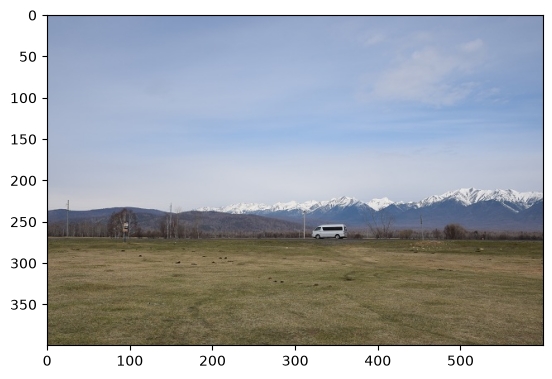

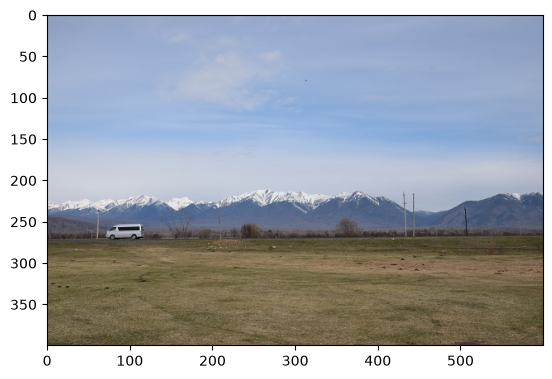

In [4]:
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.show()
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.show()

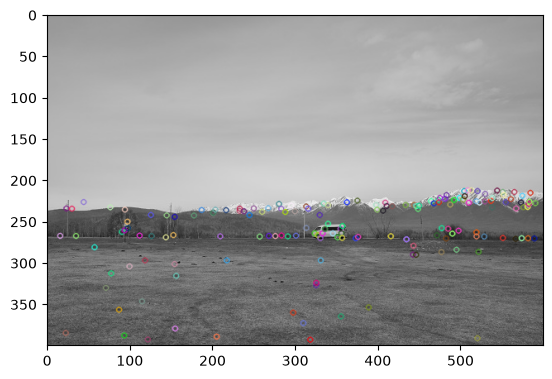

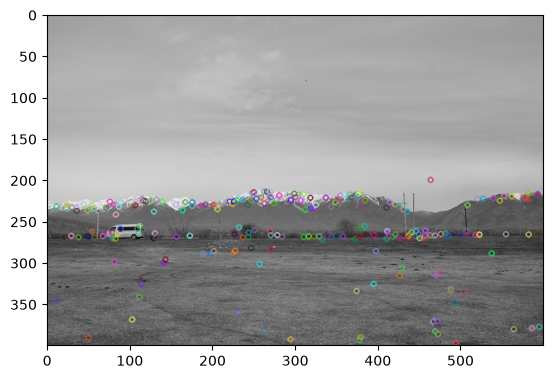

186 255
(186, 128) (255, 128)


In [5]:
# Initiate SIFT detector
sift = cv2.xfeatures2d.SIFT_create()

# find the keypoints and descriptors with SIFT
kp1, des1 = sift.detectAndCompute(img1,None)
kp2, des2 = sift.detectAndCompute(img2,None)

img = cv2.drawKeypoints(gray1,kp1,img1)
plt.imshow(img)
plt.show()

img = cv2.drawKeypoints(gray2,kp2,img2)
plt.imshow(img)
plt.show()

print(len(kp1), len(kp2))
print(des1.shape, des2.shape)

## Скільки точок інтересу на 1й картинці? На другий?
На першій картинці 186 точок інтересу, на другій 255.

## Яка розмірність матриць des1 та des2?
Розмірність des1 становить (186, 128), розмірність des2 становить (255, 128).

In [6]:
FLANN_INDEX_KDTREE = 0
index_params  = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks = 50)

flann = cv2.FlannBasedMatcher(index_params, search_params)

matches = flann.knnMatch(des1, des2, k=2)

# store all the good matches as per Lowe's ratio test.
good = []
for m,n in matches:
    # print(m.distance, n.distance)
    if m.distance < 0.7*n.distance:
        good.append(m)
print(len(good))

83


## Скільки "гарних" відповідностей було знайдено?
Знайдено 83 гарних відповідностей.

In [7]:
if len(good)>MIN_MATCH_COUNT:
    src_pts = np.float32([ kp1[m.queryIdx].pt for m in good ]).reshape(-1,1,2)
    dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good ]).reshape(-1,1,2)

    M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    matchesMask = mask.ravel().tolist()

    h,w,_ = img1.shape
    pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
    dst = cv2.perspectiveTransform(pts,M)

    img2 = cv2.polylines(img2,[np.int32(dst)],True,255,3, cv2.LINE_AA)
else:
    print ("Not enough matches are found - %d / %d" % (len(good),MIN_MATCH_COUNT) )
    matchesMask = None

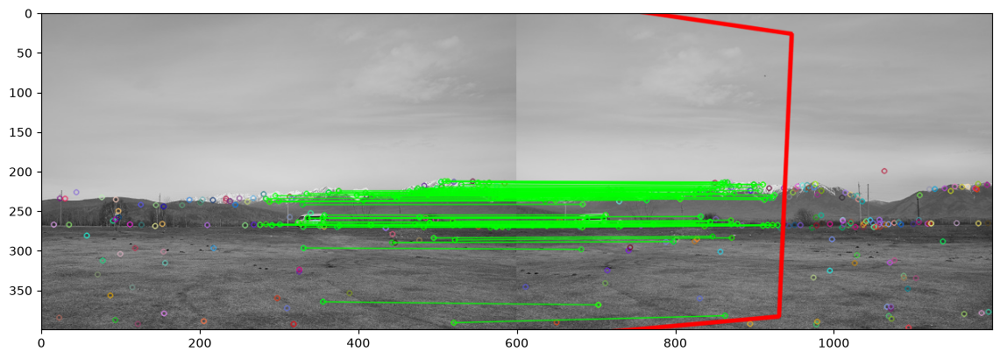

[[ 1.44967811e+00 -7.39642549e-02 -3.56573928e+02]
 [ 1.95592158e-01  1.30129523e+00 -7.79819034e+01]
 [ 7.86773789e-04 -4.05811842e-05  1.00000000e+00]]


In [8]:
draw_params = dict(matchColor = (0,255,0),    # draw matches in green color
                   singlePointColor = (255,0,0),
                   matchesMask = matchesMask, # draw only inliers
                   flags = 2)

img3 = cv2.drawMatches(img1,kp1,img2,kp2,good,None,**draw_params)

plt.figure(figsize=(14,24))
plt.imshow(img3)
plt.show()
print(M)

## Яке перетворення перекладає з однієї картинки на іншу? Випишіть у звіт.
Проективне перетворення (гомографія), яке задається матрицею M розміром 3x3:  
[[ 1.44967811e+00 -7.39642549e-02 -3.56573928e+02]  
 [ 1.95592158e-01  1.30129523e+00 -7.79819034e+01]  
 [ 7.86773789e-04 -4.05811842e-05  1.00000000e+00]]

## Що виділено червоною лінією?
Червоною лінією виділено межі першого зображення, спроектовані на друге зображення за допомогою знайденої матриці перетворення M.

In [9]:
import glob

def process_folder(folder):
    files = sorted(glob.glob(folder + '/*'))
    imgs = [cv2.imread(f, 1) for f in files]
    grays = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in imgs]
    kps, dess = [], []
    for i in range(len(imgs)):
        kp, des = sift.detectAndCompute(imgs[i], None)
        kps.append(kp)
        dess.append(des)
        img_kp = cv2.drawKeypoints(grays[i], kp, None)
        plt.imshow(img_kp)
        plt.show()
    pairs = []
    for i in range(len(imgs)):
        for j in range(i+1, len(imgs)):
            matches = flann.knnMatch(dess[i], dess[j], k=2)
            good = [m for m, n in matches if m.distance < 0.7*n.distance]
            pairs.append((len(good), i, j, good))
    pairs.sort(key=lambda x: x[0], reverse=True)
    for _, i, j, good in pairs[:5]:
        src_pts = np.float32([ kps[i][m.queryIdx].pt for m in good ]).reshape(-1,1,2)
        dst_pts = np.float32([ kps[j][m.trainIdx].pt for m in good ]).reshape(-1,1,2)
        M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
        matchesMask = mask.ravel().tolist()
        h, w, _ = imgs[i].shape
        pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
        dst = cv2.perspectiveTransform(pts, M)
        img2_poly = cv2.polylines(imgs[j].copy(), [np.int32(dst)], True, 255, 3, cv2.LINE_AA)
        draw_params = dict(matchColor=(0,255,0), singlePointColor=(255,0,0), matchesMask=matchesMask, flags=2)
        img3 = cv2.drawMatches(imgs[i], kps[i], img2_poly, kps[j], good, None, **draw_params)
        print(files[i], files[j])
        print(M)
        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
        plt.show()

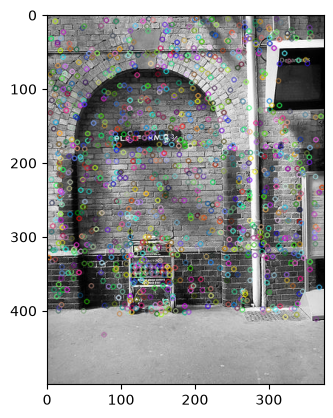

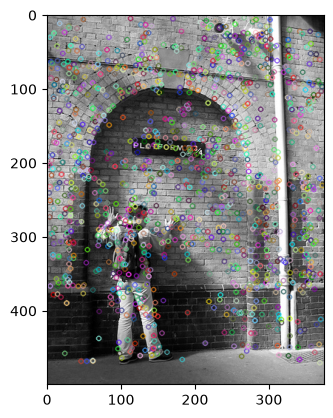

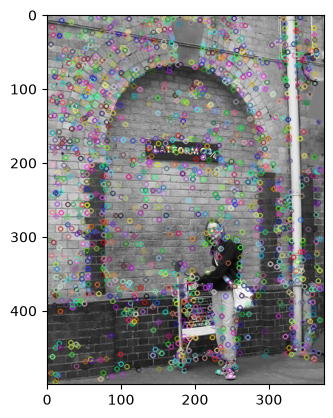

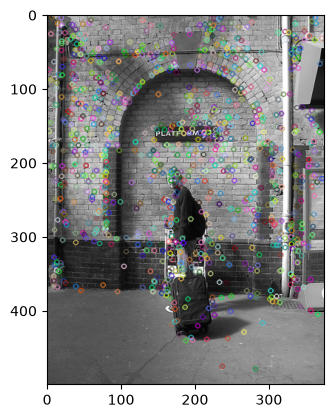

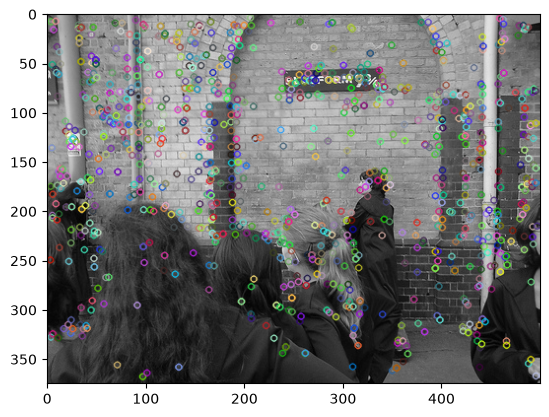

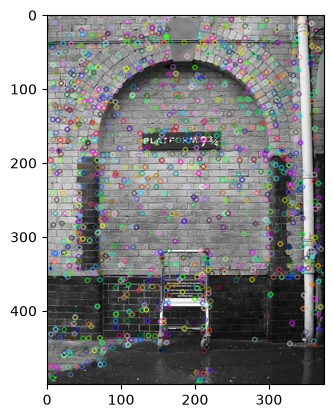

Base/5wall\ec50k_00110003.jpg Base/5wall\ec50k_00110006.jpg
[[ 8.72351914e-01 -1.08181236e-02 -1.36230954e+00]
 [-1.72932548e-01  8.06454755e-01  3.15750397e+01]
 [-6.57188521e-04 -3.87093920e-05  1.00000000e+00]]


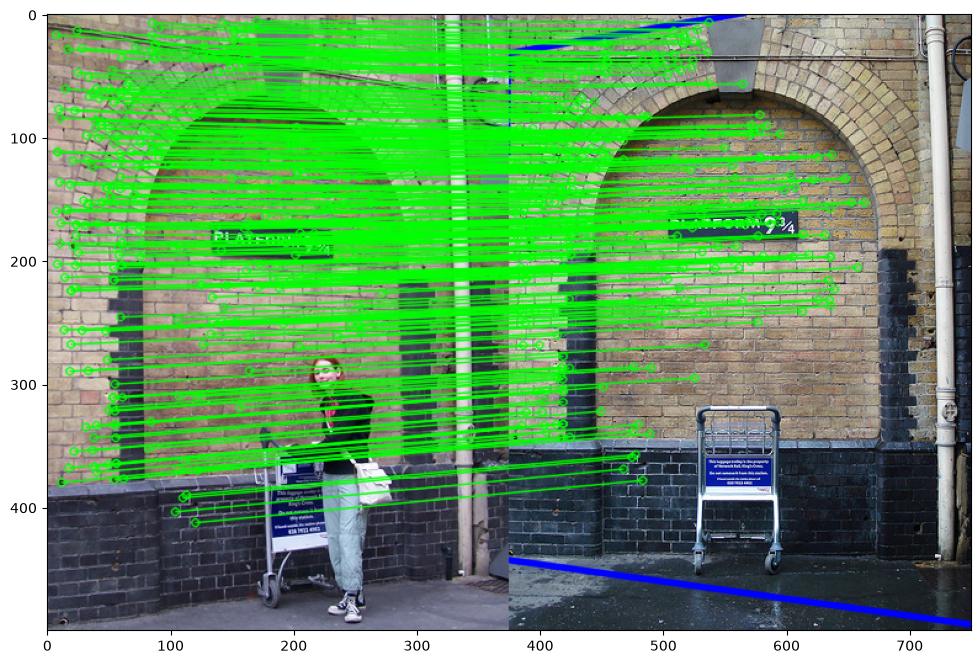

Base/5wall\ec50k_00110004.jpg Base/5wall\ec50k_00110006.jpg
[[ 1.28448882e+00 -1.44135441e-02 -5.49780691e+01]
 [ 3.26543280e-02  1.23435468e+00 -3.22542887e+01]
 [ 1.45165642e-04 -8.95973805e-05  1.00000000e+00]]


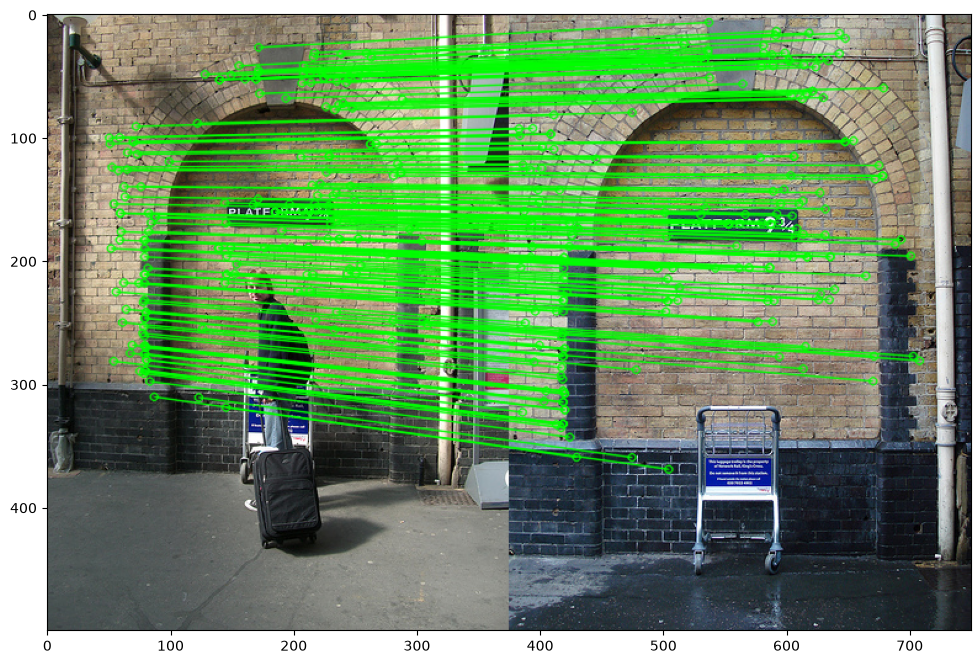

Base/5wall\ec50k_00110003.jpg Base/5wall\ec50k_00110005.jpg
[[ 7.58096407e-01  3.37384881e-02  1.17343817e+02]
 [-1.14315207e-01  8.06299320e-01 -6.58069977e+01]
 [-6.39352498e-04  1.61350203e-04  1.00000000e+00]]


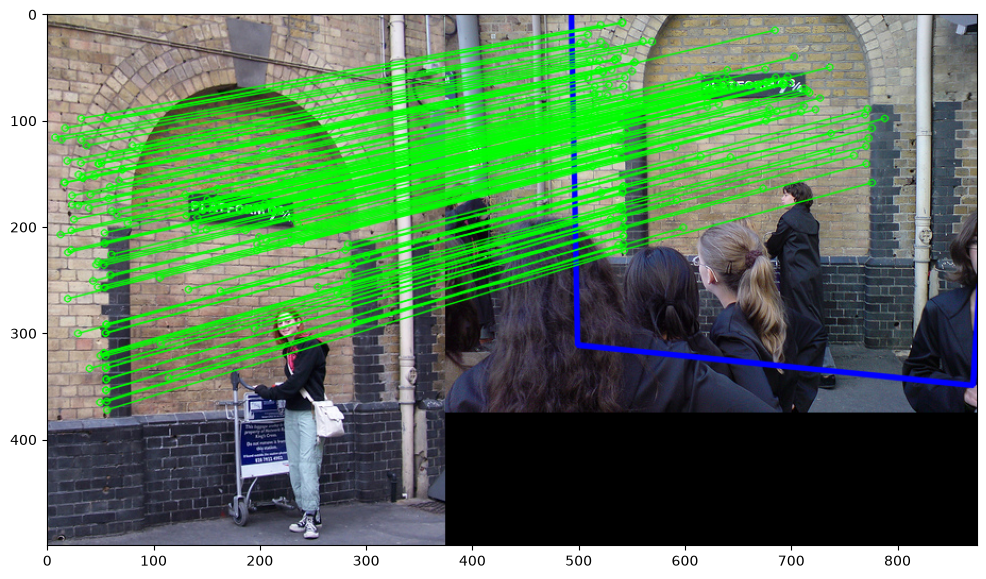

Base/5wall\ec50k_00110001.jpg Base/5wall\ec50k_00110002.jpg
[[ 1.14409995e+00 -7.65196650e-02  2.68996748e+01]
 [ 1.36107644e-01  1.02618433e+00  9.59581809e+00]
 [ 3.47464478e-04 -2.54126001e-04  1.00000000e+00]]


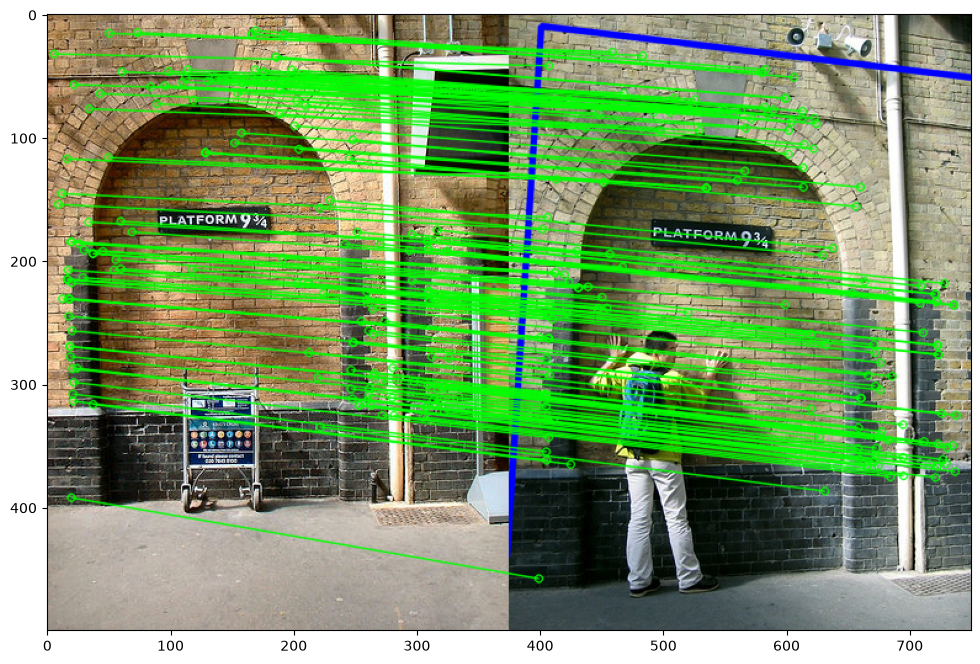

Base/5wall\ec50k_00110005.jpg Base/5wall\ec50k_00110006.jpg
[[ 1.11635798e+00 -4.46863040e-02 -1.35002697e+02]
 [ 3.29685214e-02  1.03829178e+00  9.38734797e+01]
 [ 1.05123227e-04 -1.96303794e-04  1.00000000e+00]]


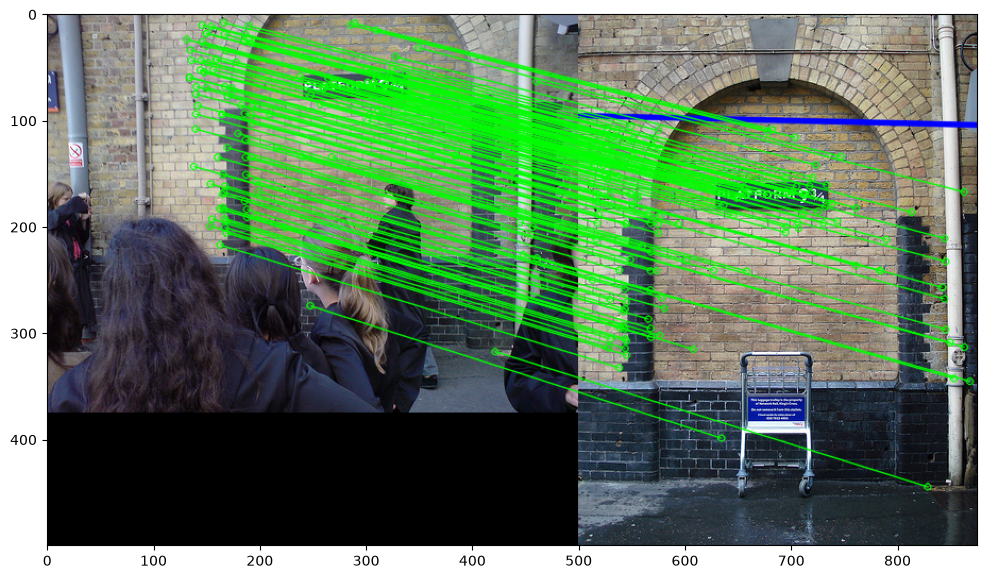

In [10]:
process_folder('Base/5wall')

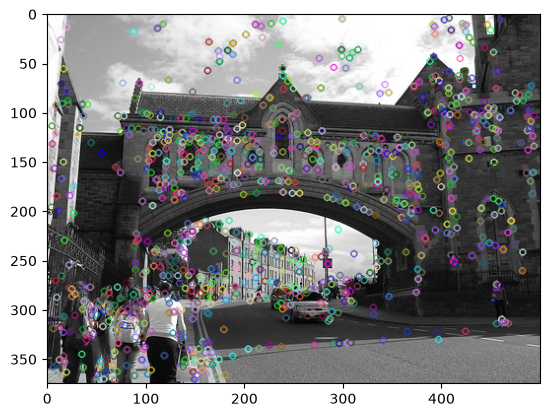

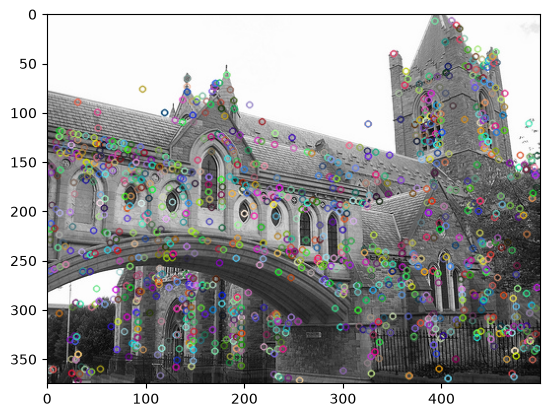

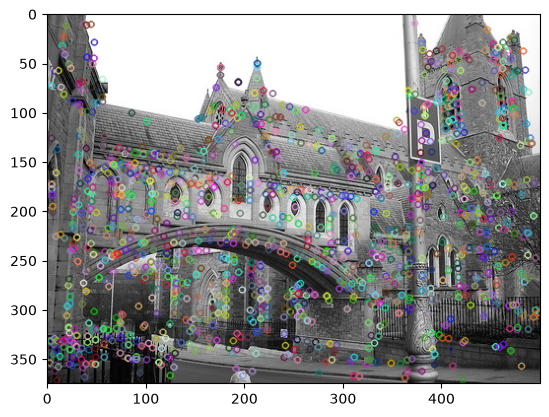

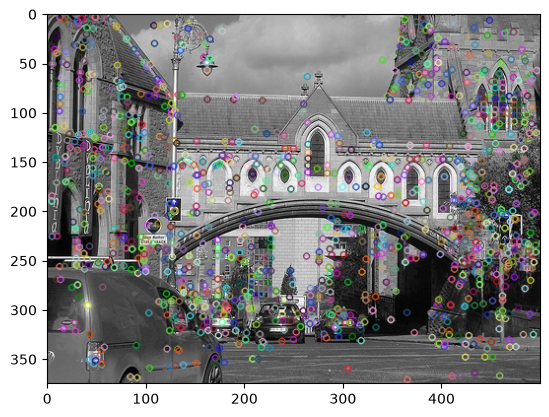

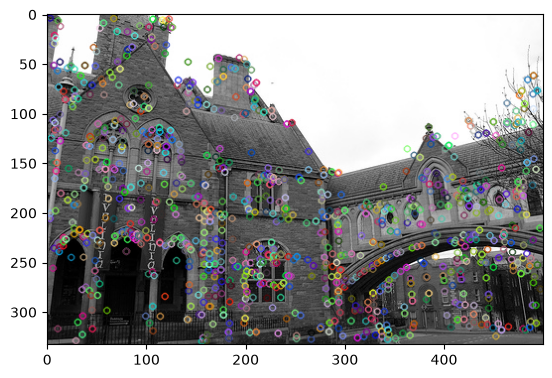

Base/6arka\ec50k_00130006.jpg Base/6arka\ec50k_00130010.jpg
[[ 7.69671156e-01  1.19446877e-01  5.16145179e+01]
 [-9.86118060e-02  9.71444513e-01  2.23487243e+01]
 [-3.80102020e-04  4.92029604e-04  1.00000000e+00]]


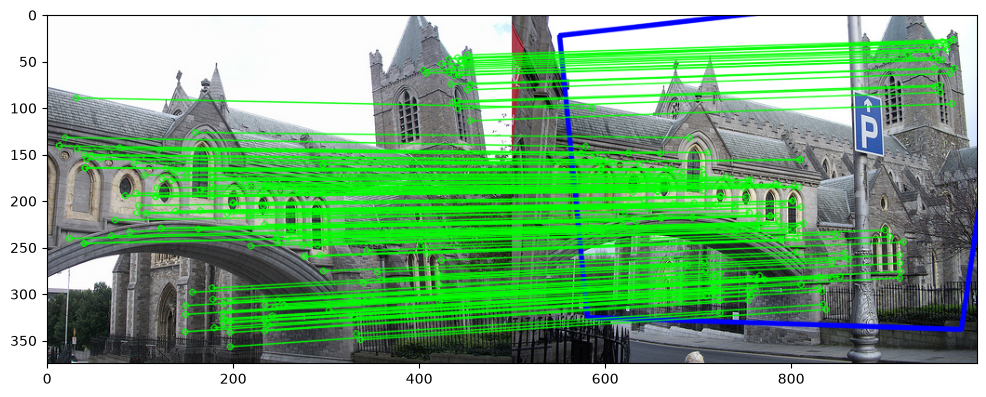

Base/6arka\ec50k_00130015.jpg Base/6arka\ec50k_00130018.jpg
[[ 2.91138868e-01  2.77516566e-01  1.93625829e+02]
 [-3.08542275e-01  7.57448489e-01  1.18383418e+02]
 [-9.62107261e-04  4.14620784e-04  1.00000000e+00]]


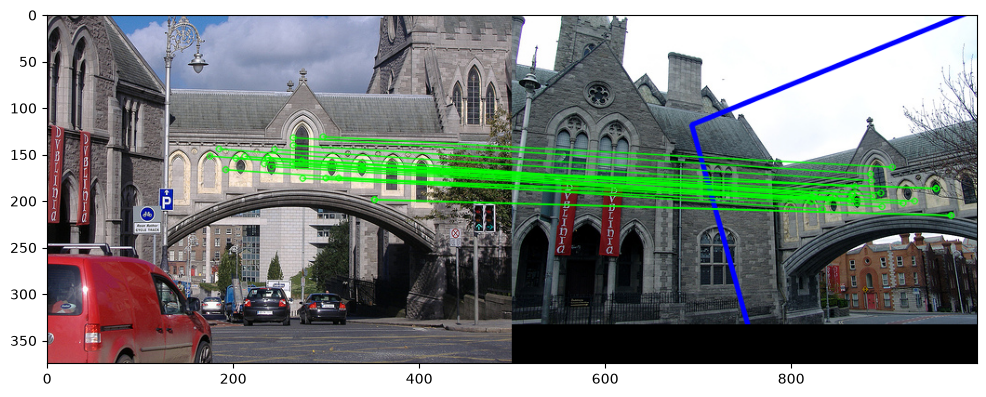

Base/6arka\ec50k_00130010.jpg Base/6arka\ec50k_00130015.jpg
[[ 6.81841991e-01  9.05923673e-02  8.54618683e+01]
 [-2.15617746e-01  8.28473320e-01  2.58253538e+01]
 [-8.46804145e-04  1.41330927e-04  1.00000000e+00]]


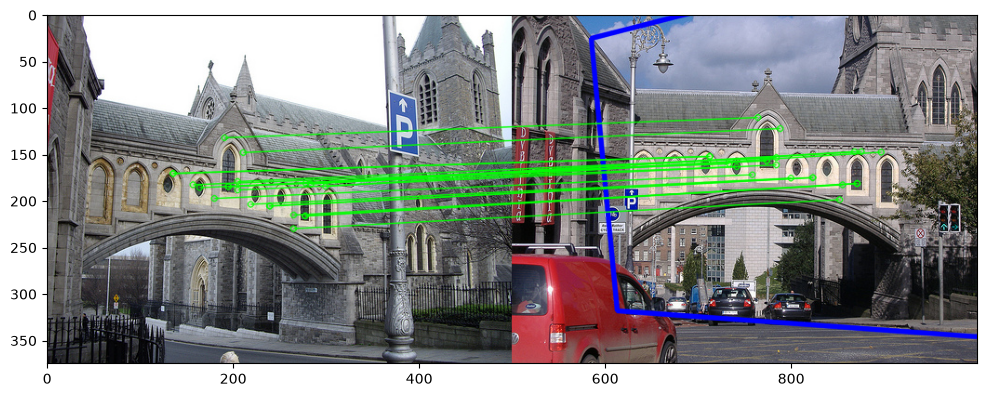

Base/6arka\ec50k_00130003.jpg Base/6arka\ec50k_00130006.jpg
[[ 2.31501064e+00 -5.94625531e-02 -2.74536824e+02]
 [ 5.86772641e-01  2.45238677e+00 -1.76498790e+02]
 [ 2.02613966e-03  1.02611795e-03  1.00000000e+00]]


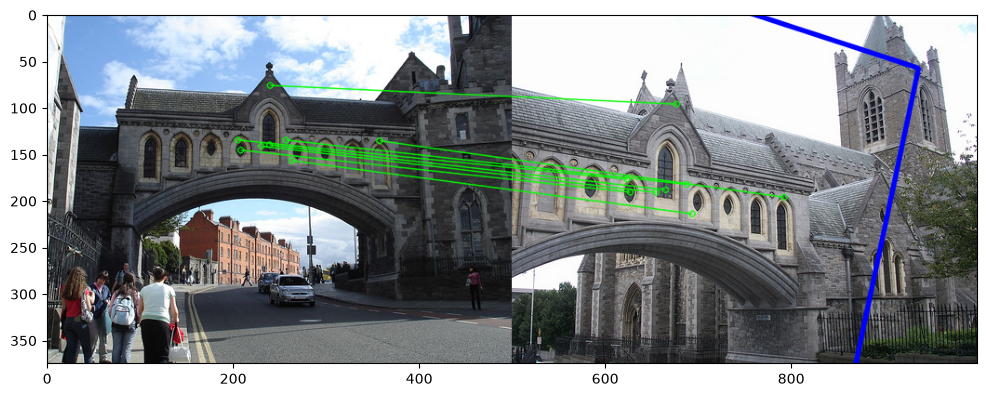

Base/6arka\ec50k_00130006.jpg Base/6arka\ec50k_00130018.jpg
[[-7.97422099e-02  3.08594305e-01  2.88496007e+02]
 [-5.51147071e-01  7.39236522e-01  1.12960986e+02]
 [-1.85760777e-03  7.81029833e-04  1.00000000e+00]]


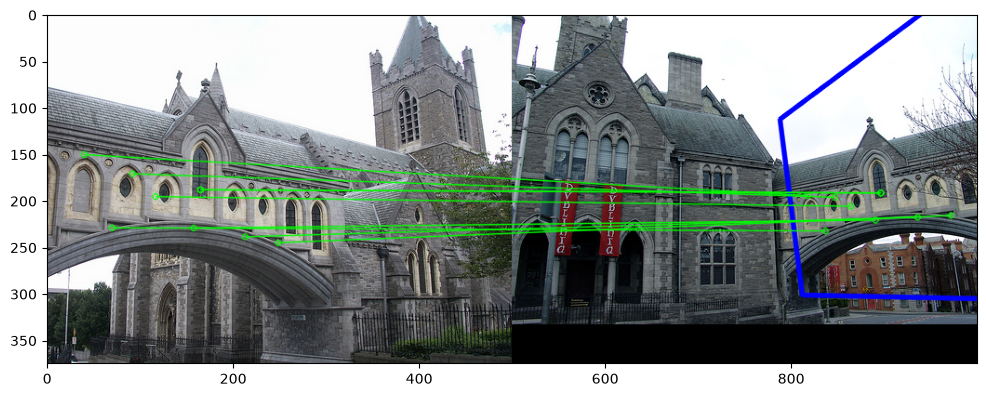

In [11]:
process_folder('Base/6arka')

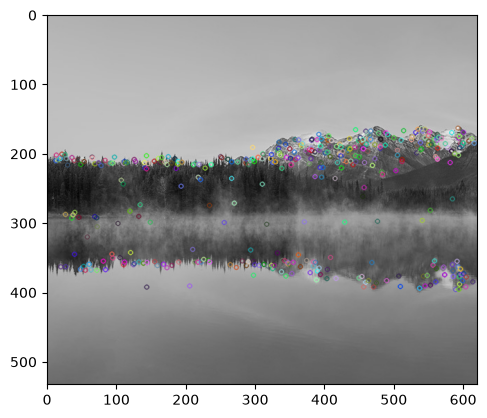

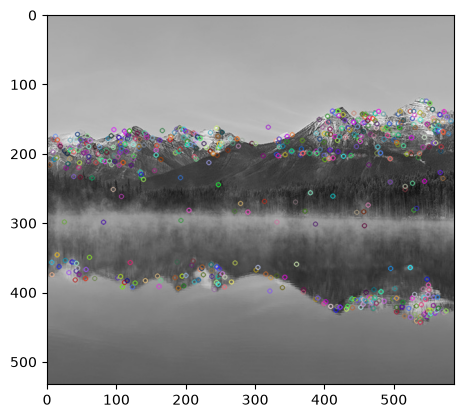

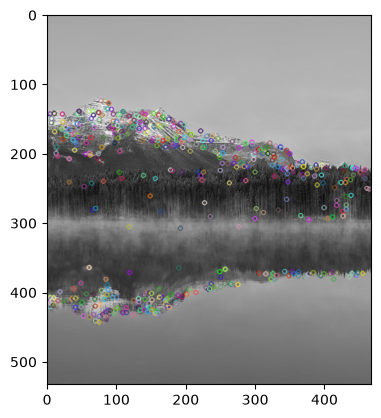

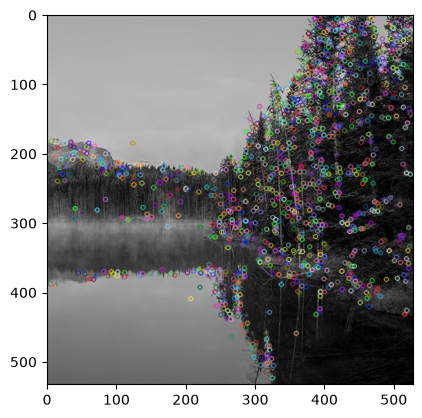

Additional\2.jpg Additional\1.jpg
[[ 1.00033514e+00 -1.19580548e-04  3.48012748e+02]
 [ 6.64709902e-05  9.99974547e-01  5.99040126e-03]
 [ 5.49423122e-07 -8.66817388e-08  1.00000000e+00]]


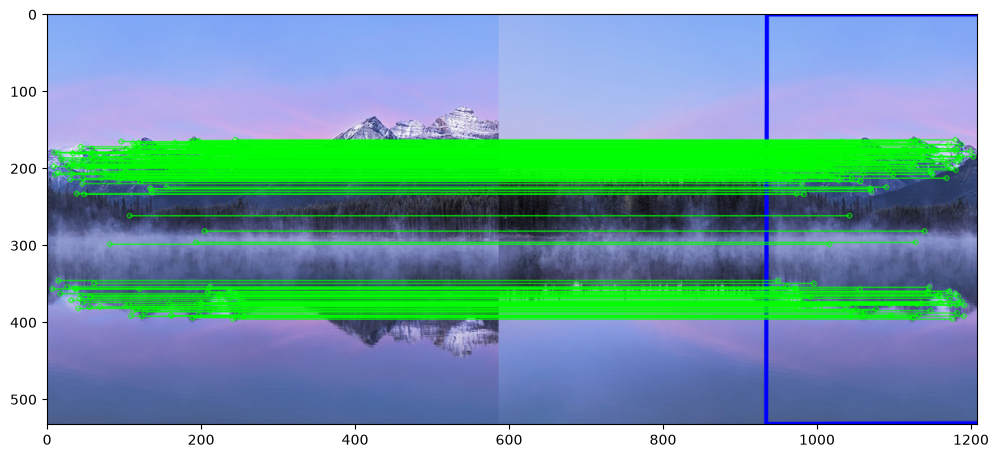

Additional\3.jpg Additional\2.jpg
[[ 9.99395473e-01  9.49568635e-05  4.62998825e+02]
 [-3.70153229e-04  1.00000146e+00  3.15161590e-02]
 [-1.09560825e-06  2.20947980e-07  1.00000000e+00]]


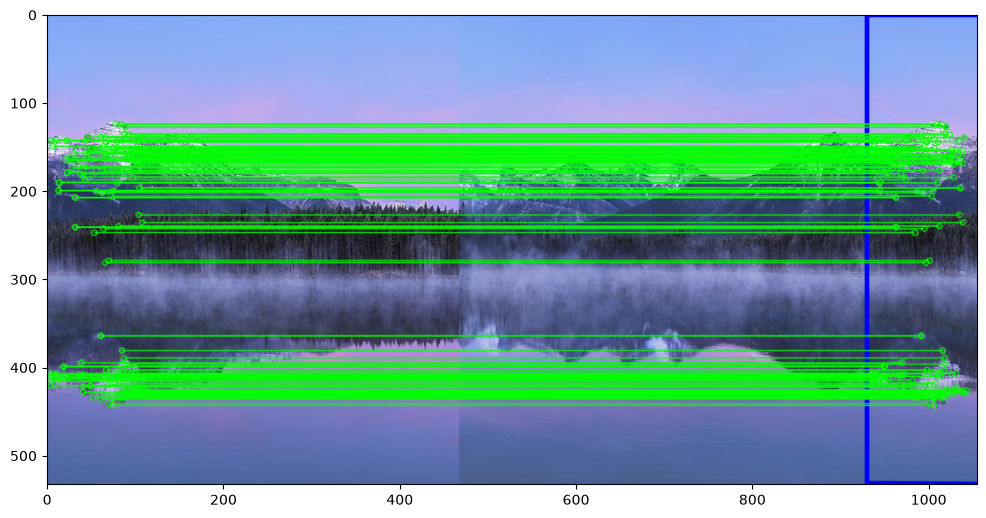

Additional\4.jpg Additional\3.jpg
[[ 1.00164000e+00  1.23653627e-03  2.60878150e+02]
 [ 6.38719848e-04  1.00187097e+00 -2.75551363e-01]
 [ 1.89145902e-06  3.05383396e-06  1.00000000e+00]]


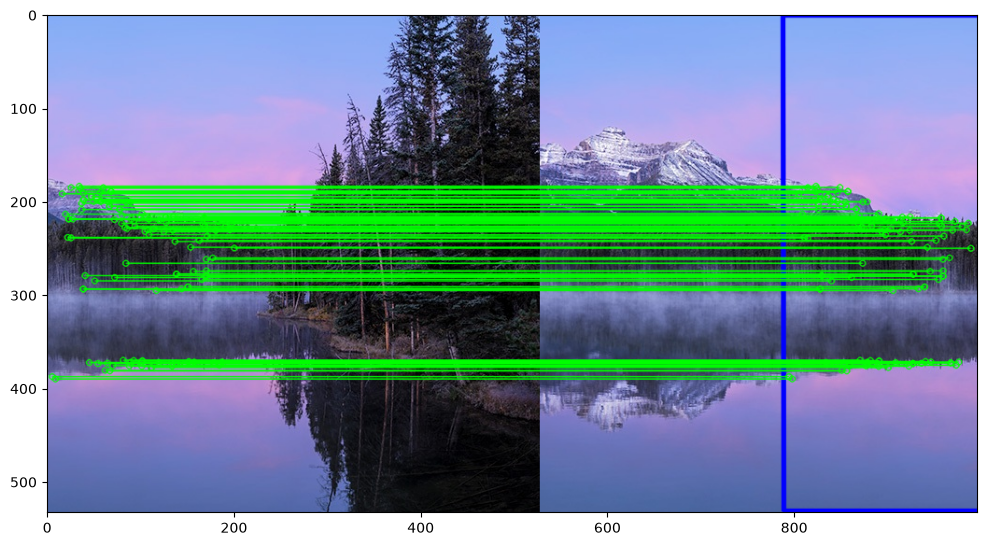

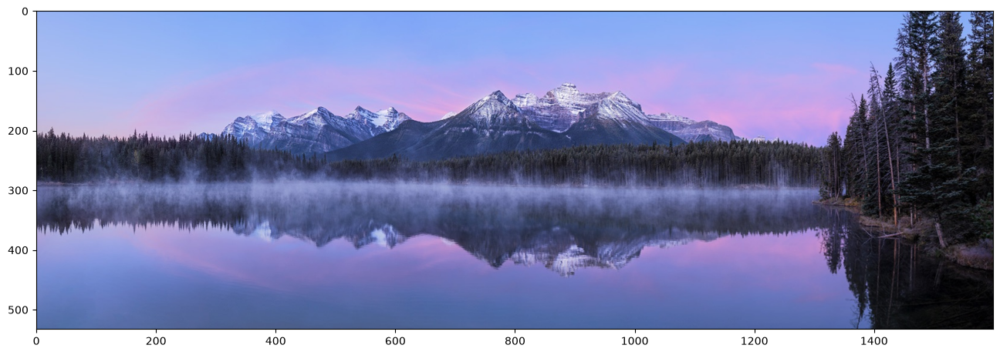

In [12]:
pano_files = sorted(glob.glob('Additional/*.jpg'))
pano_imgs = [cv2.imread(f, 1) for f in pano_files]
pano_grays = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in pano_imgs]

pano_kps, pano_dess = [], []
for i in range(len(pano_imgs)):
    kp, des = sift.detectAndCompute(pano_imgs[i], None)
    pano_kps.append(kp)
    pano_dess.append(des)
    img_kp = cv2.drawKeypoints(pano_grays[i], kp, None)
    plt.imshow(img_kp)
    plt.show()

H = np.eye(3)
pano = pano_imgs[0].copy()
for i in range(1, len(pano_imgs)):
    kp1, des1 = pano_kps[i], pano_dess[i]
    kp2, des2 = pano_kps[i-1], pano_dess[i-1]
    matches = flann.knnMatch(des1, des2, k=2)
    good = [m for m, n in matches if m.distance < 0.7*n.distance]
    src_pts = np.float32([ kp1[m.queryIdx].pt for m in good ]).reshape(-1,1,2)
    dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good ]).reshape(-1,1,2)
    M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    matchesMask = mask.ravel().tolist()

    h, w, _ = pano_imgs[i].shape
    pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
    dst_poly = cv2.perspectiveTransform(pts, M)
    img2_poly = cv2.polylines(pano_imgs[i-1].copy(), [np.int32(dst_poly)], True, 255, 3, cv2.LINE_AA)
    draw_params = dict(matchColor=(0,255,0), singlePointColor=(255,0,0), matchesMask=matchesMask, flags=2)
    img3 = cv2.drawMatches(pano_imgs[i], kp1, img2_poly, kp2, good, None, **draw_params)
    print(pano_files[i], pano_files[i-1])
    print(M)
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB))
    plt.show()

    H = H @ M
    pts_pano = np.float32([ [0,0],[0,h],[w,h],[w,0] ]).reshape(-1,1,2)
    dst = cv2.perspectiveTransform(pts_pano, H)
    warped = cv2.warpPerspective(pano_imgs[i], H, (int(dst[:,:,0].max()), pano.shape[0]))
    warped[0:pano.shape[0], 0:pano.shape[1]] = pano
    pano = warped

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(pano, cv2.COLOR_BGR2RGB))
plt.show()